# 05 · Análise espacial, perfil das vítimas e síntese

| Seção | Conteúdo | Arquivo |
|---|---|---|
| 1 | Densidade espacial (KDE) + pontos por gravidade, 2×2 | `05_mapa_kde_2x2.png` |
| 2 | Hotspots: trechos de rodovia (km) e células urbanas (~500 m) | `05_hotspots.png` |
| 3 | Perfil das vítimas (rodovias e vias urbanas) | `05_perfil_vitimas*.png` |
| 4 | Letalidade por tipo de vítima: pedestre, motociclista, ciclista, ocupantes | `05_fatalidade_tipo_vitima.png` |
| 5 | Vítimas fatais por tipo e ano | `05_fatais_tipo_vitima_ano.png` |
| 6 | Evolução mensal empilhada por gravidade | `05_evolucao_mensal_gravidade.png` |
| 7 | Tabela-síntese e radar dos 4 segmentos | `05_radar_4segmentos.png` |

**Vítima** = pessoa com lesão LEVE, GRAVE ou FATAL (ilesos e "não disponível" ficam fora dos
perfis). **Letalidade** = vítimas fatais ÷ vítimas.

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import polars as pl
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns
from src import config, viz

viz.tema()
sin = pl.read_parquet(config.DATA_PROCESSED / "sinistros.parquet").to_pandas()
pes = pl.read_parquet(config.DATA_PROCESSED / "pessoas.parquet").to_pandas()
MUN, VIAS = config.MUNICIPIOS, config.GRUPOS_VIA
geo = sin[sin.coord_valida]
print(f"Coordenadas válidas: {len(geo):,} de {len(sin):,} ({len(geo)/len(sin):.1%})")

Coordenadas válidas: 25,273 de 25,858 (97.7%)


## 1. Distribuição espacial (KDE + pontos coloridos por gravidade)

  ✔ figura salva: reports/figures/05_mapa_kde_2x2.png


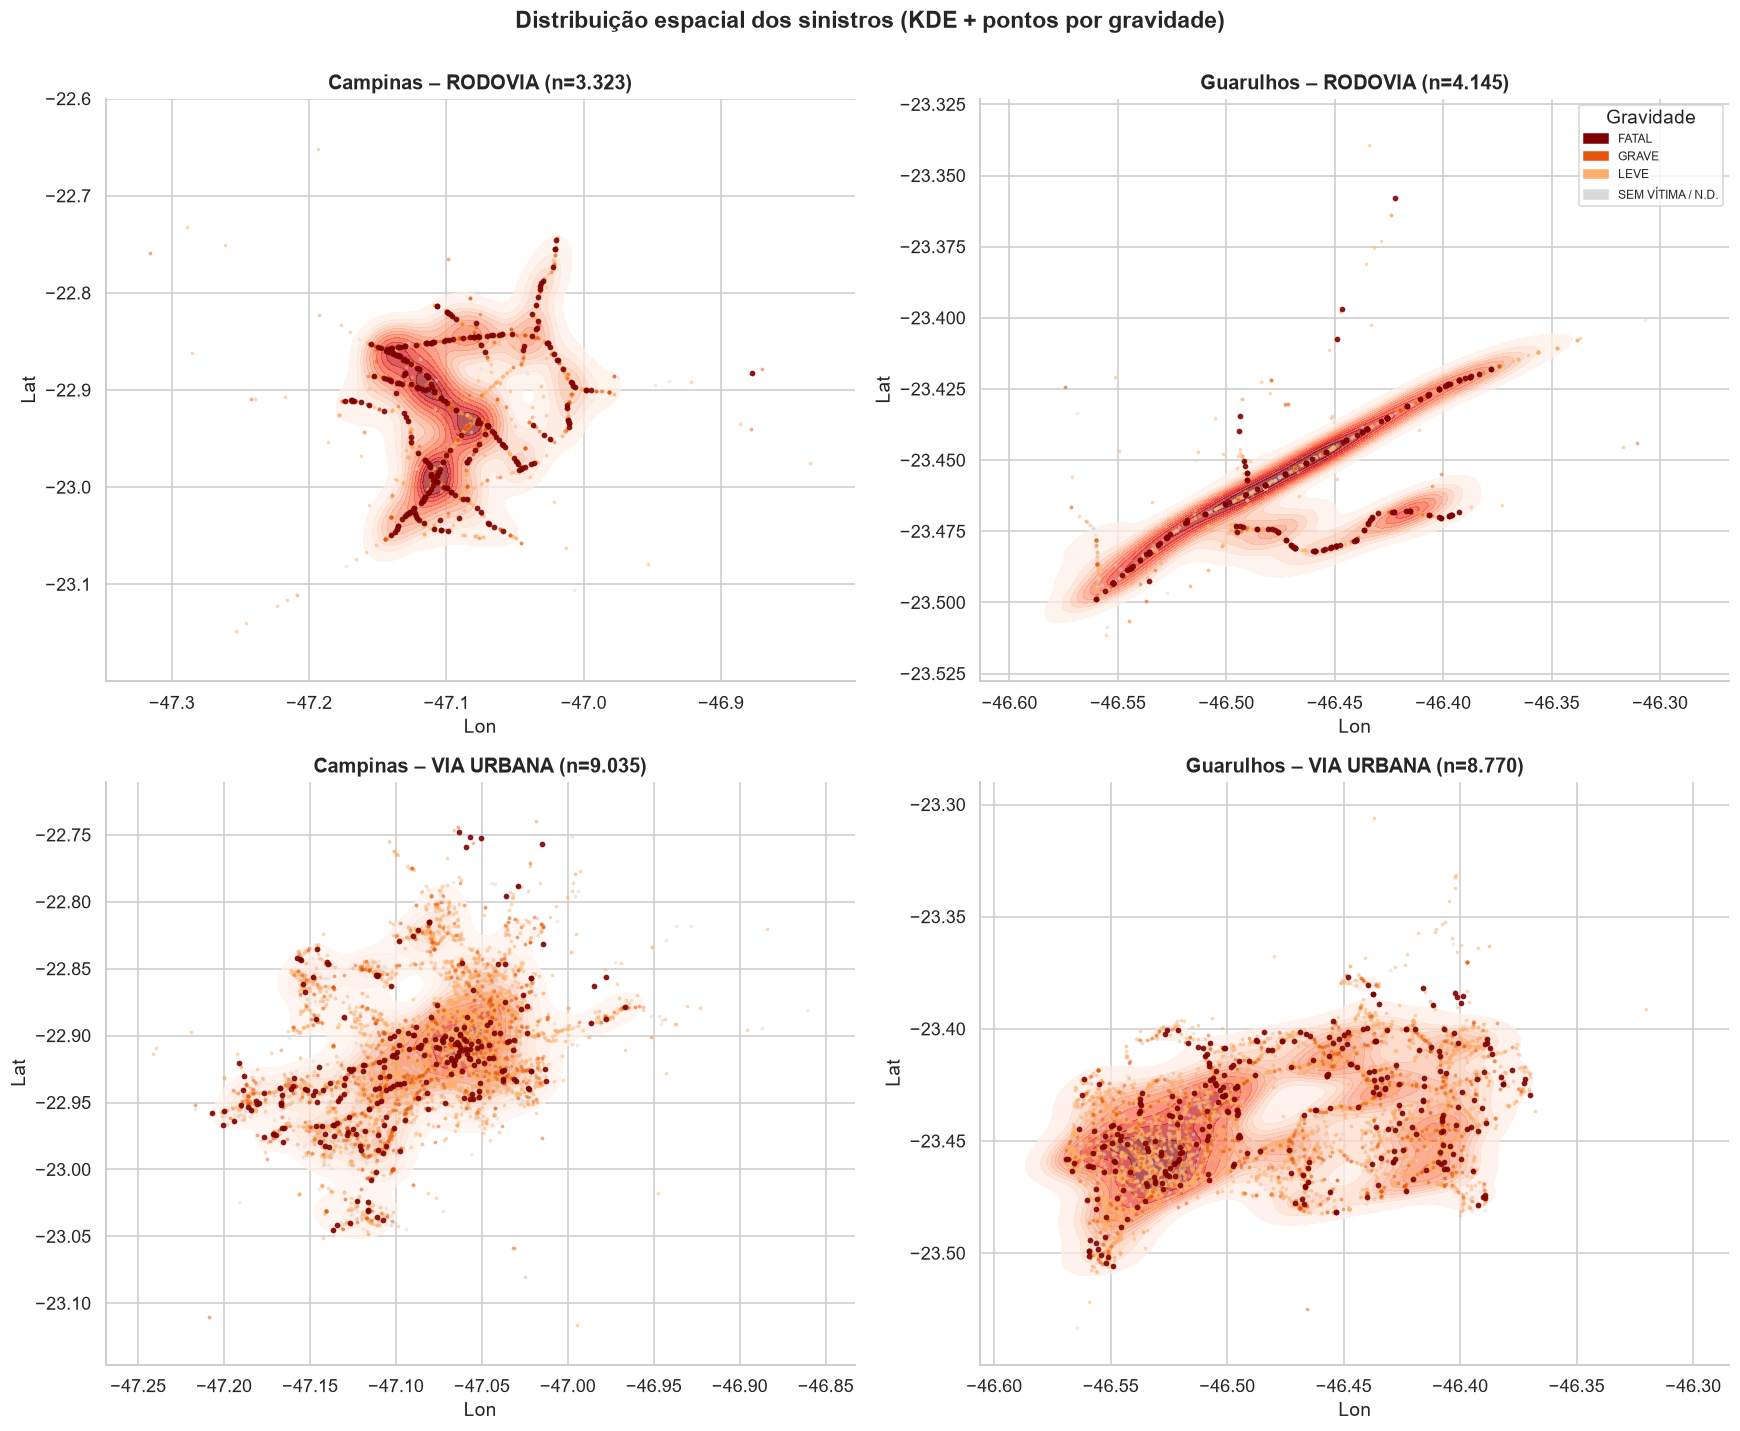

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for i, via in enumerate(VIAS):
    for j, mun in enumerate(MUN):
        ax = axes[i, j]
        d = geo[(geo.municipio == mun) & (geo.grupo_via == via)]
        sns.kdeplot(data=d, x="longitude", y="latitude", fill=True, thresh=0.05, levels=12,
                    cmap="Reds", alpha=.7, ax=ax)
        for g in config.ORDEM_GRAVIDADE:
            dg = d[d.gravidade == g]
            ax.scatter(dg.longitude, dg.latitude, s=6 if g != "FATAL" else 14,
                       color=config.CORES_GRAV[g], alpha=.5 if g != "FATAL" else .9, lw=0)
        ax.set(title=f"{mun.title()} – {via} (n={len(d):,})".replace(",", "."), xlabel="Lon", ylabel="Lat")
axes[0, 1].legend(handles=[mpatches.Patch(color=config.CORES_GRAV[g], label=g)
                           for g in reversed(config.ORDEM_GRAVIDADE)], title="Gravidade", fontsize=8)
fig.suptitle("Distribuição espacial dos sinistros (KDE + pontos por gravidade)", fontweight="bold", y=1.0)
plt.tight_layout(); viz.salvar_fig(fig, "05_mapa_kde_2x2"); plt.show()

## 2. Hotspots
- **Rodovias:** trecho = rodovia + km inteiro (`numero_logradouro`).
- **Vias urbanas:** o InfoSiga traz número do imóvel, não km; por isso o hotspot urbano é uma
  **célula de ~500 m** (grade de 0,005° de lat/lon), identificada pela via mais frequente nela.

  ✔ tabela salva: reports/tables/05_hotspots.csv


  ✔ figura salva: reports/figures/05_hotspots.png


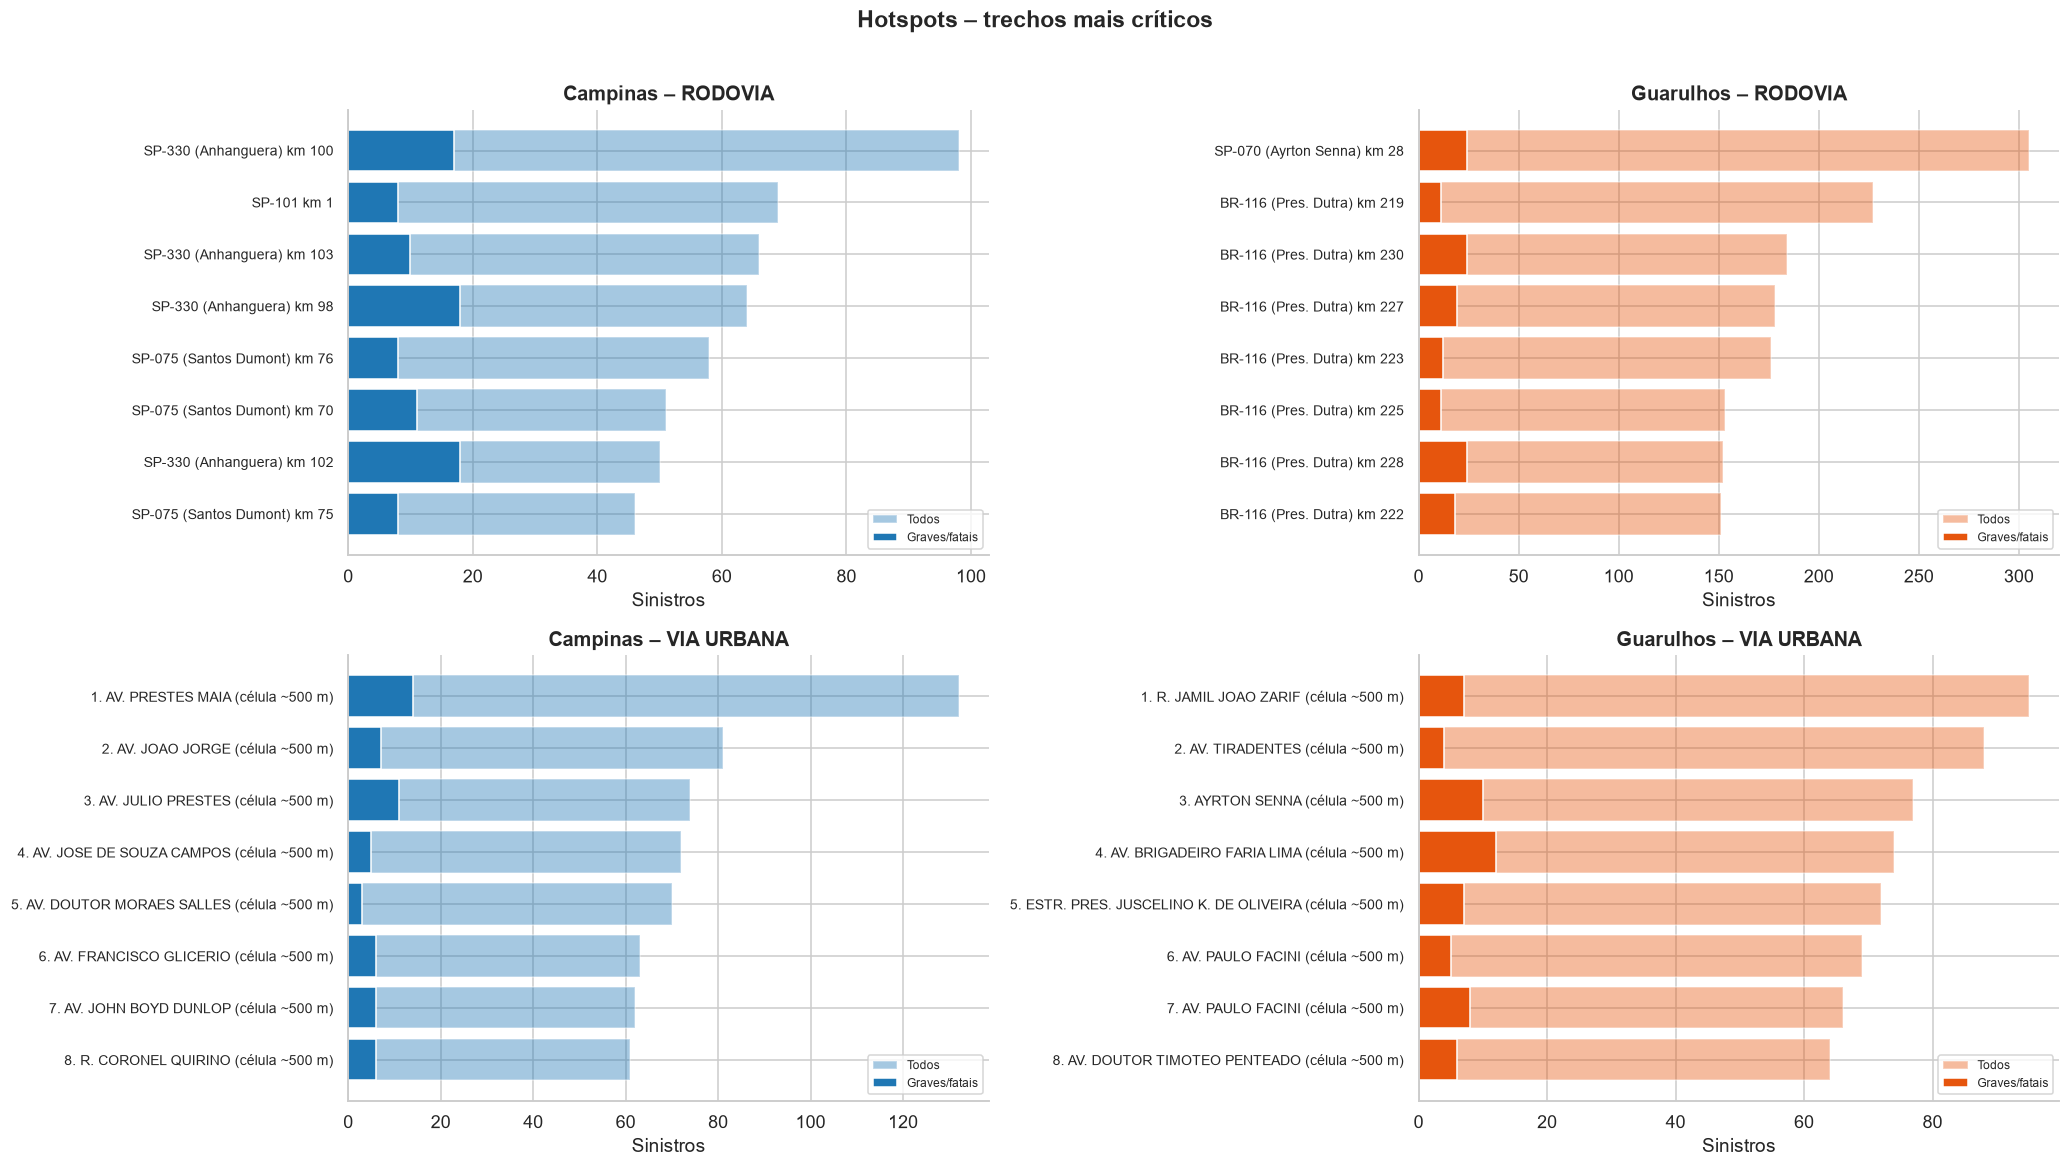

In [3]:
rod = sin[(sin.grupo_via == "RODOVIA") & sin.km.notna() & ~sin.via_nome.isin(["OUTRA / N.D.", "N.D."])].copy()
rod["trecho"] = rod.via_nome + " km " + rod.km.round(0).astype(int).astype(str)
urb = geo[geo.grupo_via == "VIA URBANA"].copy()
urb["cel"] = (urb.latitude / 0.005).round().astype(int).astype(str) + "_" + (urb.longitude / 0.005).round().astype(int).astype(str)
via_cel = urb.groupby("cel").via_nome.agg(lambda s: s.value_counts().index[0])
urb["trecho"] = urb.cel.map(via_cel) + " (célula " + urb.cel.str.replace("_", "/") + ")"

def top_hot(d, n=8):
    return (d.groupby(["municipio", "grupo_via", "trecho"])
             .agg(sin=("id_sinistro", "count"), gf=("grave_fatal", "sum"), fat=("fatal", "sum"))
             .reset_index().sort_values("sin", ascending=False).groupby("municipio").head(n))
hot = pd.concat([top_hot(rod), top_hot(urb)], ignore_index=True)
viz.salvar_tab(hot, "05_hotspots")

fig, axes = plt.subplots(2, 2, figsize=(19, 10.5))
for i, via in enumerate(VIAS):
    for j, mun in enumerate(MUN):
        ax = axes[i, j]
        d = hot[(hot.municipio == mun) & (hot.grupo_via == via)].sort_values("sin")
        rot = d.trecho.str.replace(r" \(célula .*\)", " (célula ~500 m)", regex=True) if via == "VIA URBANA" else d.trecho
        rot = [f"{len(d)-k}. {t}" if via == "VIA URBANA" else t for k, t in enumerate(rot)]
        ax.barh(rot, d.sin, color=config.CORES[mun], alpha=.4, label="Todos")
        ax.barh(rot, d.gf, color=config.CORES[mun], label="Graves/fatais")
        ax.set(title=f"{mun.title()} – {via}", xlabel="Sinistros"); ax.legend(fontsize=8, loc="lower right")
        ax.tick_params(axis="y", labelsize=9)
fig.suptitle("Hotspots – trechos mais críticos", fontweight="bold", y=1.01)
plt.tight_layout(); viz.salvar_fig(fig, "05_hotspots"); plt.show()

## 3. Perfil das vítimas
Faixas etárias calculadas a partir da `idade`: 0–17, 18–29, 30–44, 45–59, 60+.

Vítimas (leve+grave+fatal): 25,656


  ✔ figura salva: reports/figures/05_perfil_vitimas.png


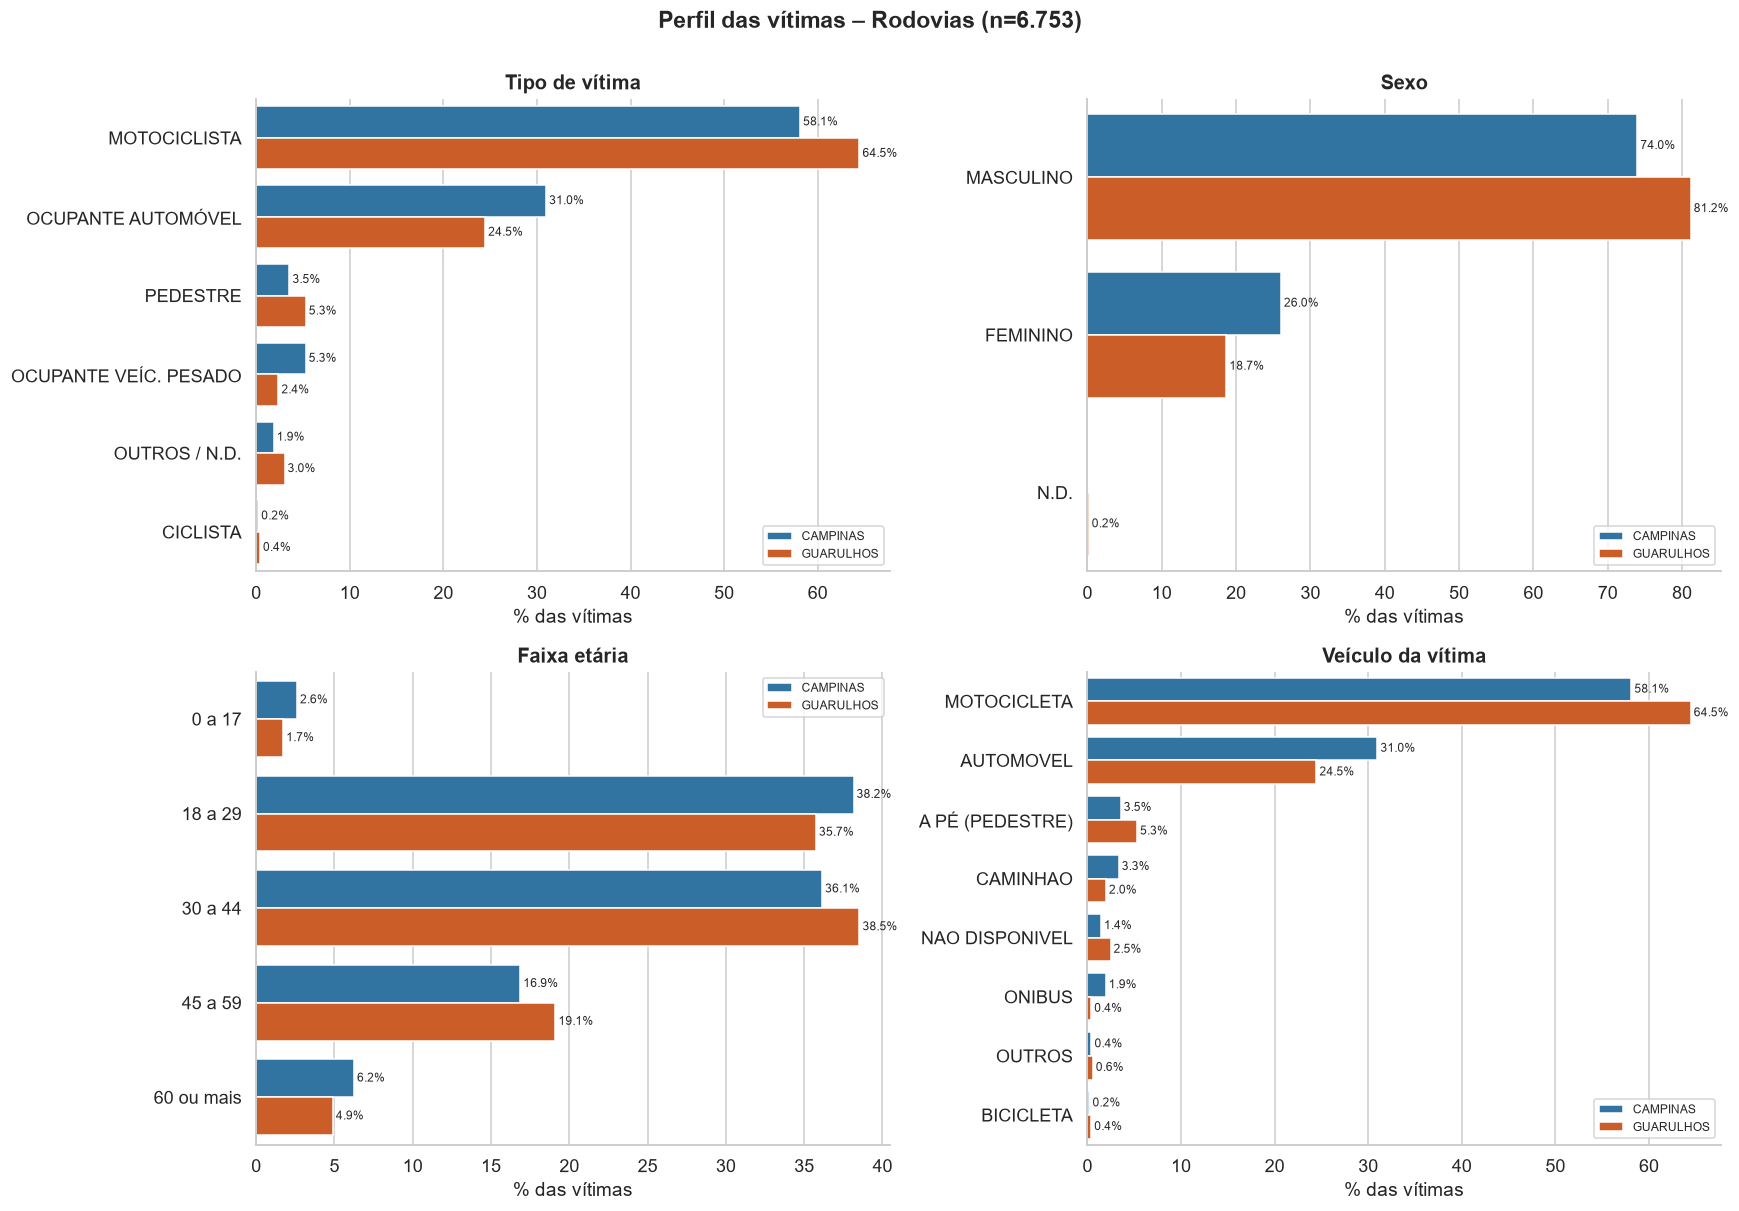

  ✔ figura salva: reports/figures/05_perfil_vitimas_urbanas.png


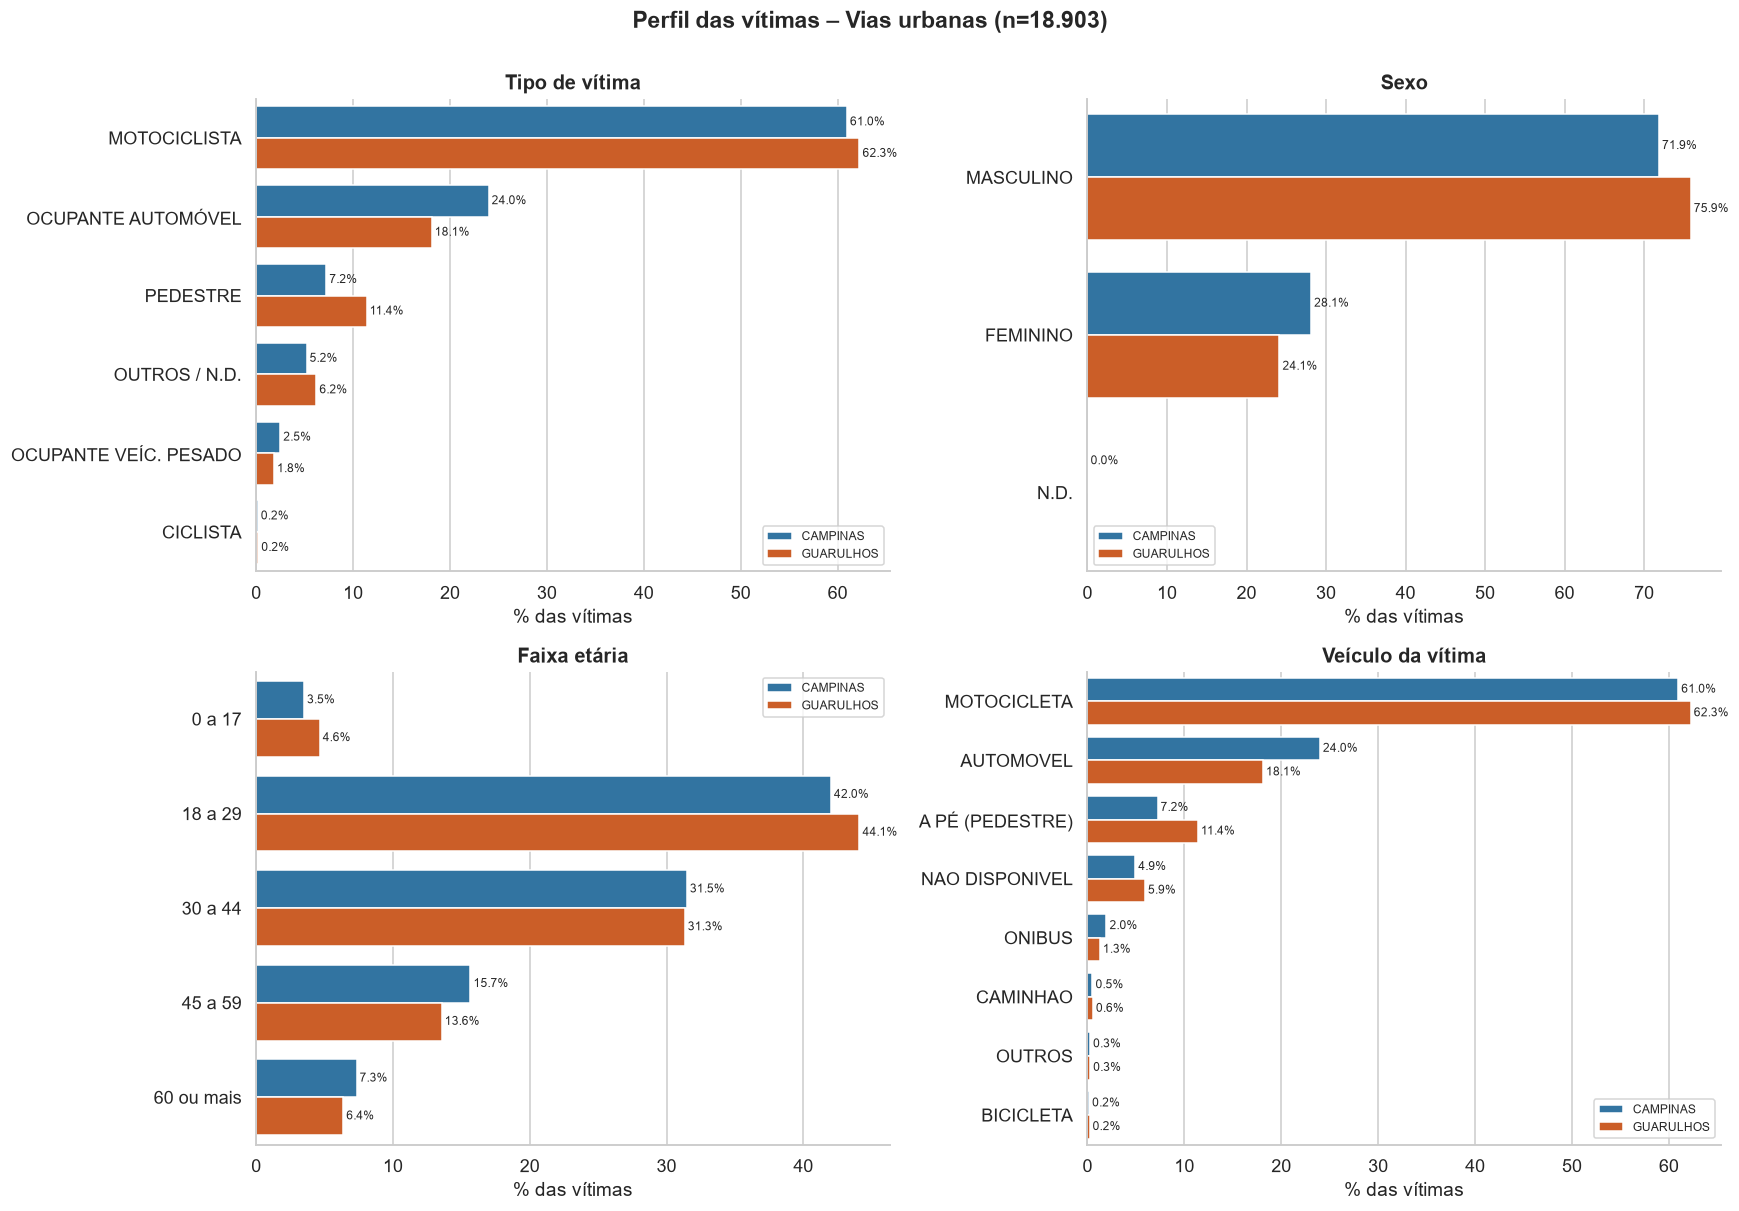

  ✔ tabela salva: reports/tables/05_perfil_vitimas.csv


In [4]:
vit = pes[pes.gravidade_lesao.isin(["LEVE", "GRAVE", "FATAL"])].copy()
vit["faixa"] = pd.cut(vit.idade, [-1, 17, 29, 44, 59, 200],
                      labels=["0 a 17", "18 a 29", "30 a 44", "45 a 59", "60 ou mais"]).astype(str).replace("nan", "N.D.")
vit["sexo"] = vit.sexo.replace({"NAO DISPONIVEL": "N.D."})
vit["veiculo_vitima"] = vit.veiculo_vitima.where(vit.tipo_vitima != "PEDESTRE", "A PÉ (PEDESTRE)")
print(f"Vítimas (leve+grave+fatal): {len(vit):,}")

def perfil(via, nome):
    vars_ = {"categoria_vitima": "Tipo de vítima", "sexo": "Sexo", "faixa": "Faixa etária",
             "veiculo_vitima": "Veículo da vítima"}
    d0 = vit[vit.grupo_via == via]
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    saida = []
    for ax, (v, tit) in zip(axes.ravel(), vars_.items()):
        t = d0.groupby(["municipio", v]).size().reset_index(name="n")
        t["pct"] = t.groupby("municipio").n.transform(lambda x: x / x.sum() * 100)
        ordem = (["0 a 17", "18 a 29", "30 a 44", "45 a 59", "60 ou mais", "N.D."] if v == "faixa"
                 else t.groupby(v).n.sum().sort_values(ascending=False).index.tolist()[:8])
        sns.barplot(data=t[t[v].isin(ordem)], y=v, x="pct", hue="municipio", order=[o for o in ordem if o in set(t[v])],
                    hue_order=MUN, palette=config.CORES, ax=ax)
        viz.rotulos_pct(ax, fontsize=8)
        ax.set(title=tit, xlabel="% das vítimas", ylabel=""); ax.legend(fontsize=8, title="")
        saida.append(t.rename(columns={v: "categoria"}).assign(variavel=tit, grupo_via=via))
    fig.suptitle(f"Perfil das vítimas – {'Rodovias' if via == 'RODOVIA' else 'Vias urbanas'} "
                 f"(n={len(d0):,})".replace(",", "."), fontweight="bold", y=1.0)
    plt.tight_layout(); viz.salvar_fig(fig, nome); plt.show()
    return pd.concat(saida)

perf = pd.concat([perfil("RODOVIA", "05_perfil_vitimas"), perfil("VIA URBANA", "05_perfil_vitimas_urbanas")])
_ = viz.salvar_tab(perf, "05_perfil_vitimas")

## 4. Letalidade por tipo de vítima
% das vítimas que morreram, por categoria. Rótulo mostra também o nº de vítimas (n).
Categorias com menos de 30 vítimas no segmento não são exibidas (estimativa instável) — isso
afeta principalmente **ciclistas**, pouco identificados no InfoSiga pelo veículo da vítima;
para bicicletas, use a análise por sinistro (`envolve_bicicleta`) dos notebooks 03 e 04.

  ✔ tabela salva: reports/tables/05_fatalidade_tipo_vitima.csv


  ✔ figura salva: reports/figures/05_fatalidade_tipo_vitima.png


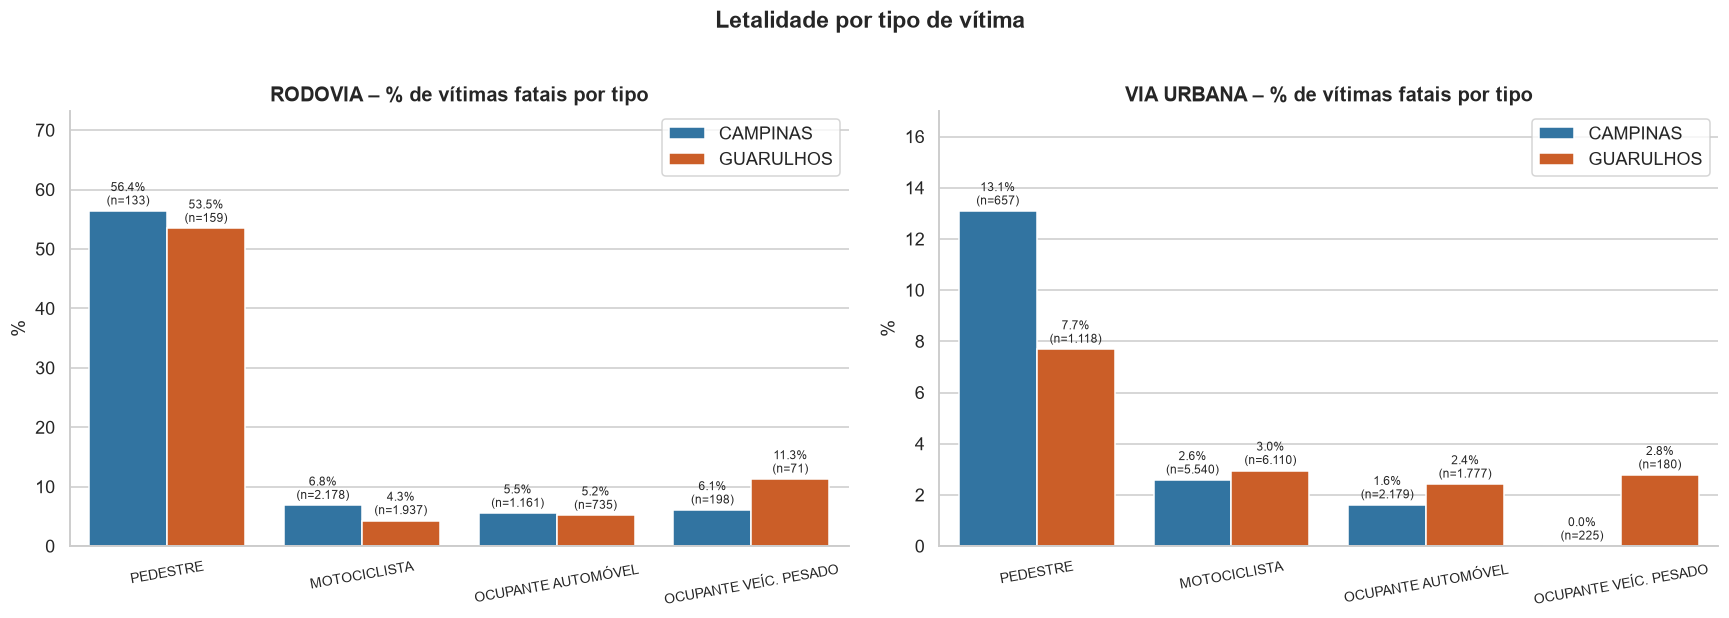

In [5]:
let = (vit.groupby(["grupo_via", "municipio", "categoria_vitima"])
          .agg(n=("id_pessoa", "count"), fatais=("gravidade_lesao", lambda s: (s == "FATAL").sum()))
          .reset_index())
let["pct_fatal"] = (let.fatais / let.n * 100).round(2)
viz.salvar_tab(let, "05_fatalidade_tipo_vitima")
ordem = ["PEDESTRE", "MOTOCICLISTA", "CICLISTA", "OCUPANTE AUTOMÓVEL", "OCUPANTE VEÍC. PESADO"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, via in zip(axes, VIAS):
    d = let[(let.grupo_via == via) & (let.n >= 30) & let.categoria_vitima.isin(ordem)]
    sns.barplot(data=d, x="categoria_vitima", y="pct_fatal", hue="municipio",
                order=[o for o in ordem if o in set(d.categoria_vitima)], hue_order=MUN,
                palette=config.CORES, ax=ax)
    for cont, mun in zip(ax.containers, MUN):
        dm = d[d.municipio == mun].set_index("categoria_vitima")
        labs = [f"{dm.pct_fatal.get(o, np.nan):.1f}%\n(n={dm.n.get(o, 0):,})".replace(",", ".")
                for o in [o for o in ordem if o in set(d.categoria_vitima)]]
        ax.bar_label(cont, labels=labs, padding=2, fontsize=8)
    ax.set(title=f"{via} – % de vítimas fatais por tipo", xlabel="", ylabel="%")
    ax.tick_params(axis="x", labelsize=9, rotation=10); ax.legend(title="")
    ax.set_ylim(0, d.pct_fatal.max() * 1.3)
fig.suptitle("Letalidade por tipo de vítima", fontweight="bold", y=1.02)
plt.tight_layout(); viz.salvar_fig(fig, "05_fatalidade_tipo_vitima"); plt.show()

## 5. Vítimas fatais por tipo e ano

  ✔ tabela salva: reports/tables/05_fatais_tipo_vitima_ano.csv


  ✔ figura salva: reports/figures/05_fatais_tipo_vitima_ano.png


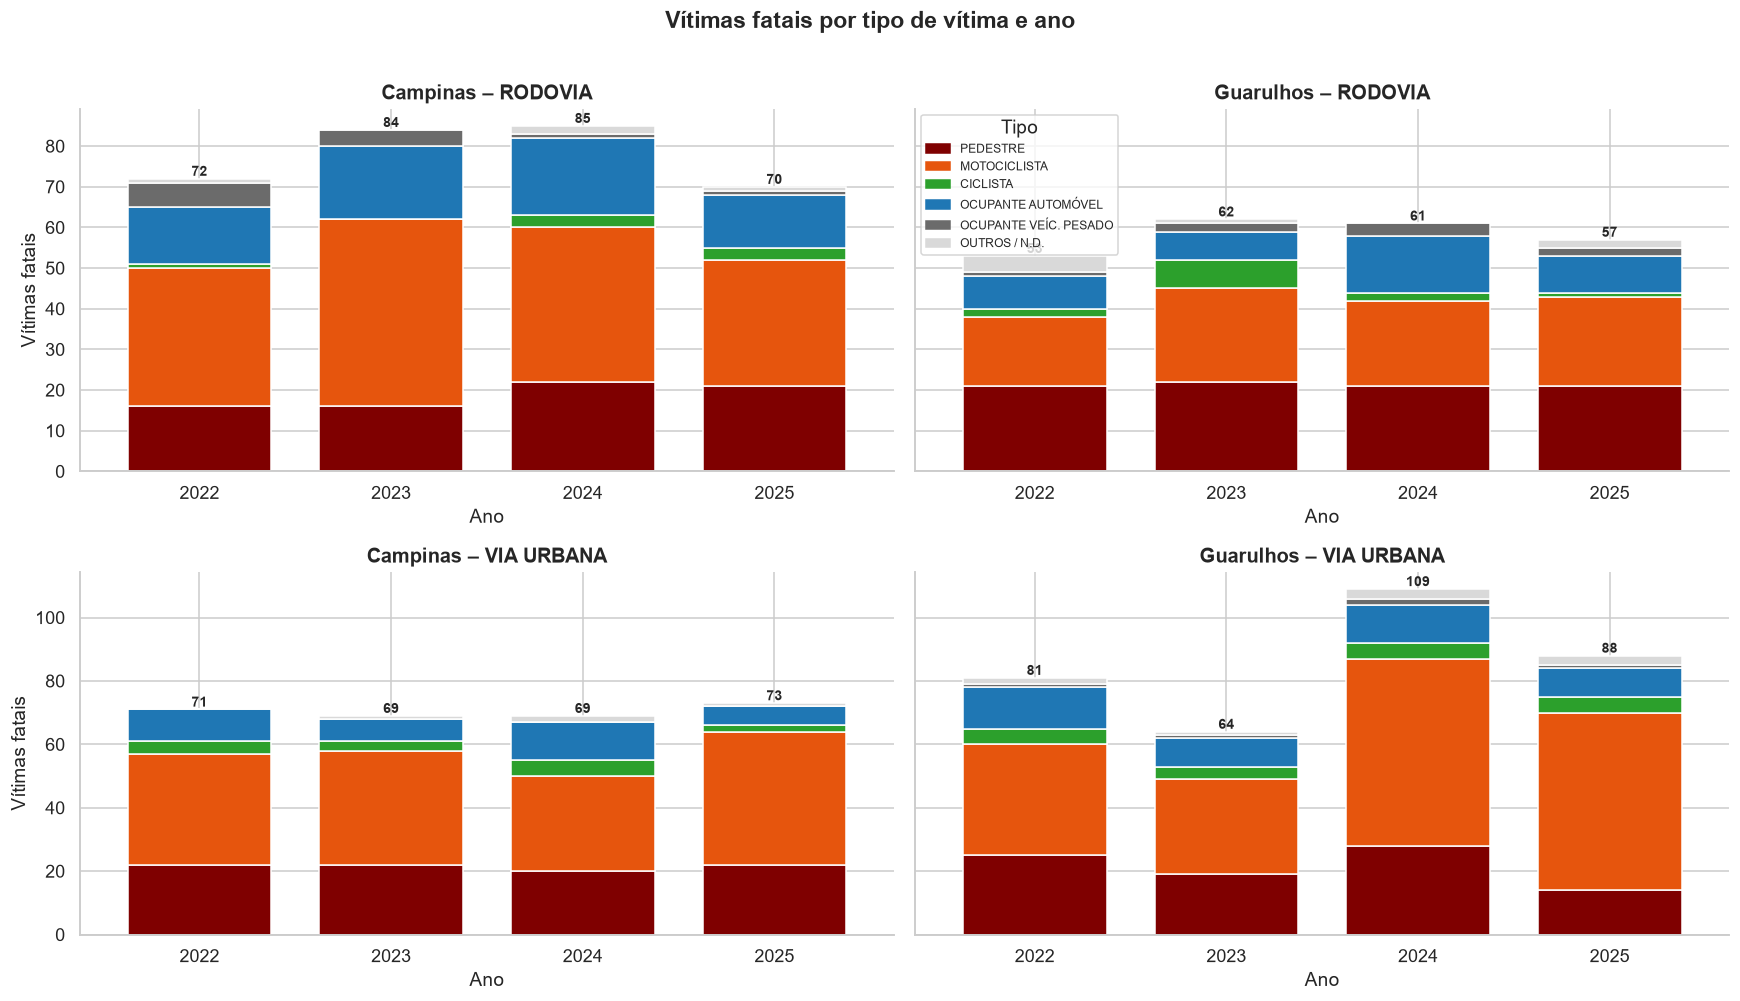

In [6]:
fa = (vit[vit.gravidade_lesao == "FATAL"].groupby(["municipio", "grupo_via", "ano", "categoria_vitima"])
         .size().reset_index(name="fatais"))
viz.salvar_tab(fa, "05_fatais_tipo_vitima_ano")
cores_cat = {"PEDESTRE": "#7f0000", "MOTOCICLISTA": "#e6550d", "CICLISTA": "#2ca02c",
             "OCUPANTE AUTOMÓVEL": "#1f77b4", "OCUPANTE VEÍC. PESADO": "#6b6b6b", "OUTROS / N.D.": "#d9d9d9"}
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey="row")
for i, via in enumerate(VIAS):
    for j, mun in enumerate(MUN):
        ax = axes[i, j]
        p = (fa[(fa.municipio == mun) & (fa.grupo_via == via)]
               .pivot(index="ano", columns="categoria_vitima", values="fatais")
               .reindex(index=config.ANOS, columns=list(cores_cat)).fillna(0))
        p.plot(kind="bar", stacked=True, color=cores_cat.values(), ax=ax, width=.75, legend=False)
        for k, tot in enumerate(p.sum(axis=1)):
            ax.text(k, tot, f"{int(tot)}", ha="center", va="bottom", fontsize=9, fontweight="bold")
        ax.set(title=f"{mun.title()} – {via}", xlabel="Ano", ylabel="Vítimas fatais"); ax.tick_params(axis="x", rotation=0)
axes[0, 1].legend(handles=[mpatches.Patch(color=c, label=k) for k, c in cores_cat.items()], fontsize=8, title="Tipo")
fig.suptitle("Vítimas fatais por tipo de vítima e ano", fontweight="bold", y=1.01)
plt.tight_layout(); viz.salvar_fig(fig, "05_fatais_tipo_vitima_ano"); plt.show()

## 6. Evolução mensal empilhada por gravidade

  ✔ figura salva: reports/figures/05_evolucao_mensal_gravidade.png


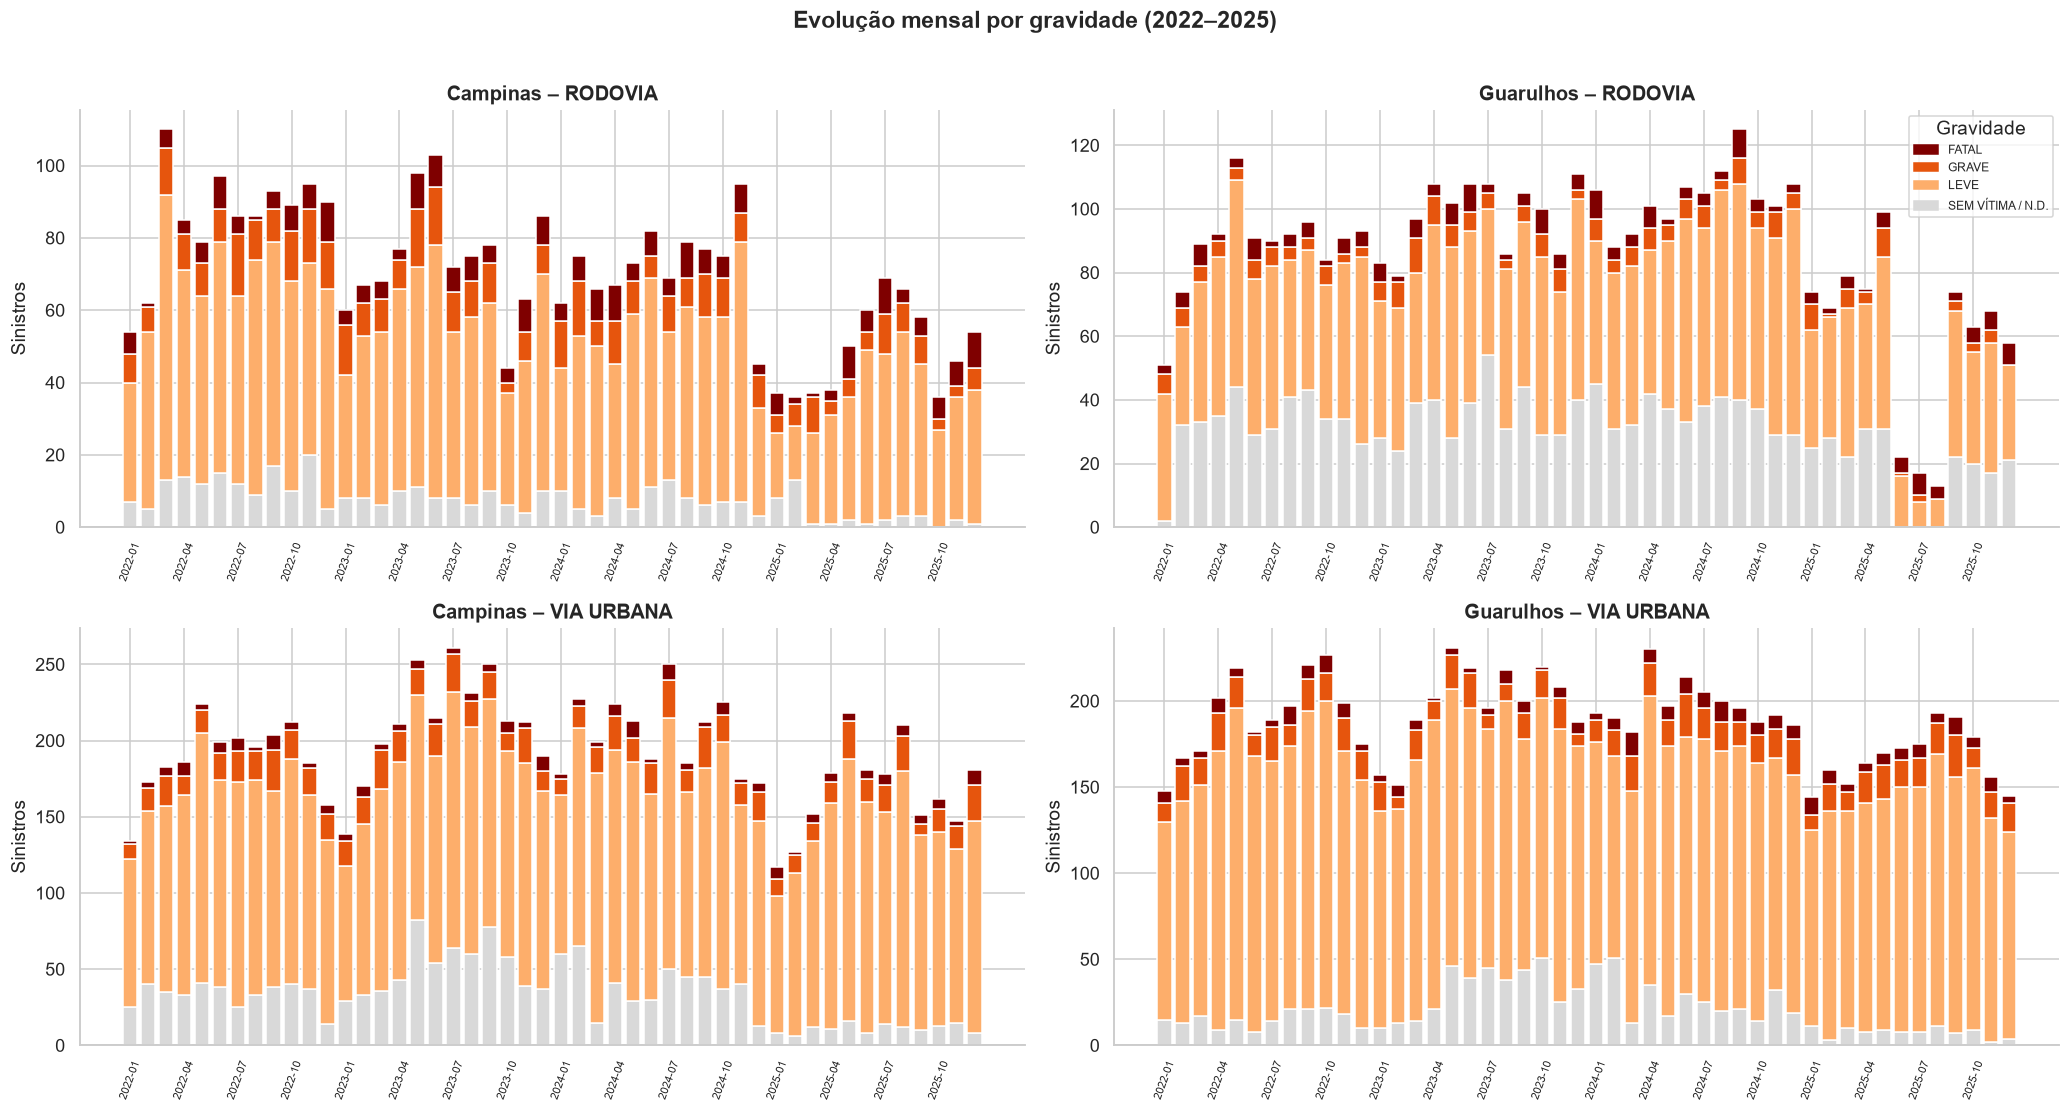

In [7]:
gm = sin.groupby(["municipio", "grupo_via", "ano_mes", "gravidade"]).size().reset_index(name="n")
meses = sorted(sin.ano_mes.unique())
fig, axes = plt.subplots(2, 2, figsize=(19, 10))
for i, via in enumerate(VIAS):
    for j, mun in enumerate(MUN):
        ax = axes[i, j]
        p = (gm[(gm.municipio == mun) & (gm.grupo_via == via)]
               .pivot(index="ano_mes", columns="gravidade", values="n")
               .reindex(index=meses, columns=config.ORDEM_GRAVIDADE).fillna(0))
        bot = np.zeros(len(p))
        for g in config.ORDEM_GRAVIDADE:
            ax.bar(range(len(p)), p[g], bottom=bot, color=config.CORES_GRAV[g], width=.8, label=g)
            bot += p[g].values
        ax.set_xticks(range(0, len(p), 3)); ax.set_xticklabels(meses[::3], rotation=70, fontsize=7)
        ax.set(title=f"{mun.title()} – {via}", ylabel="Sinistros")
axes[0, 1].legend(handles=[mpatches.Patch(color=config.CORES_GRAV[g], label=g)
                           for g in reversed(config.ORDEM_GRAVIDADE)], title="Gravidade", fontsize=8)
fig.suptitle("Evolução mensal por gravidade (2022–2025)", fontweight="bold", y=1.01)
plt.tight_layout(); viz.salvar_fig(fig, "05_evolucao_mensal_gravidade"); plt.show()

## 7. Tabela-síntese e radar dos 4 segmentos

In [8]:
sin["noite"] = sin.periodo.isin(["Noite", "Madrugada"])
ind = {"grave_fatal": "Grave/Fatal%", "envolve_moto": "Moto%", "envolve_pesado": "Pesado%",
       "envolve_pedestre": "Pedestre%", "envolve_bicicleta": "Bicicleta%",
       "tp_capotamento": "Capotamento%", "fim_semana": "Fim sem%", "noite": "Noite/Madrug.%"}
sint = (sin.groupby(["municipio", "grupo_via"])
           .agg(sinistros=("id_sinistro", "count"), fatais=("fatal", "sum"), **{k: (k, "mean") for k in ind})
           .reset_index())
for k in ind:
    sint[k] = (sint[k] * 100).round(1)
sint["pop"] = sint.municipio.map(config.POPULACAO)
sint["sin_100k_ano"] = (sint.sinistros / sint["pop"] * 1e5 / len(config.ANOS)).round(1)
sint["fat_100k_ano"] = (sint.fatais / sint["pop"] * 1e5 / len(config.ANOS)).round(2)
viz.salvar_tab(sint.rename(columns=ind), "05_sintese_indicadores")
sint.rename(columns=ind).set_index(["municipio", "grupo_via"]).T

  ✔ tabela salva: reports/tables/05_sintese_indicadores.csv


municipio         CAMPINAS               GUARULHOS            
grupo_via          RODOVIA  VIA URBANA     RODOVIA  VIA URBANA
sinistros          3369.00     9250.00     4188.00     9051.00
fatais              294.00      274.00      219.00      329.00
Grave/Fatal%         22.10       12.10       11.10       12.20
Moto%                57.60       56.90       64.80       64.20
Pesado%              14.00        8.70       15.50        9.80
Pedestre%             4.10        7.30        4.90       12.50
Bicicleta%            1.60        2.00        1.60        2.50
Capotamento%          6.90        2.20        2.40        1.00
Fim sem%             26.00       27.50       23.80       29.50
Noite/Madrug.%       42.10       38.00       39.00       41.50
pop             1139047.00  1139047.00  1291771.00  1291771.00
sin_100k_ano         73.90      203.00       81.10      175.20
fat_100k_ano          6.45        6.01        4.24        6.37

  ✔ figura salva: reports/figures/05_radar_4segmentos.png


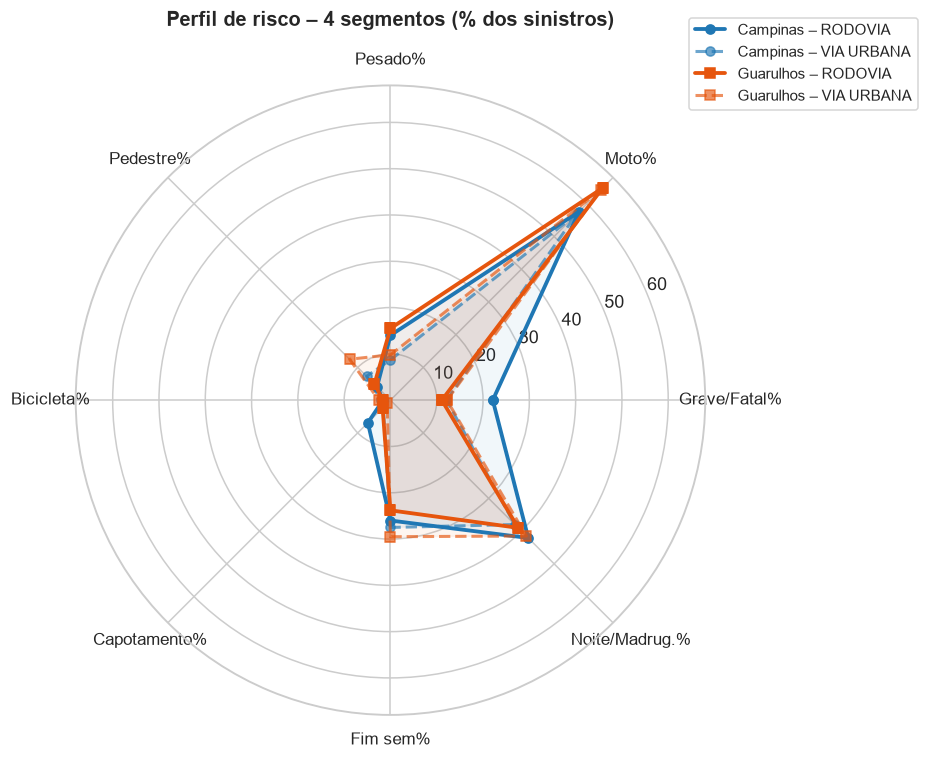

In [9]:
cols = list(ind)
ang = np.linspace(0, 2 * np.pi, len(cols), endpoint=False).tolist(); ang += ang[:1]
fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
for r in sint.itertuples():
    v = [getattr(r, c) for c in cols]; v += v[:1]
    rodovia = r.grupo_via == "RODOVIA"
    ax.plot(ang, v, marker="o" if r.municipio == "CAMPINAS" else "s", ls="-" if rodovia else "--",
            lw=2.5 if rodovia else 2, color=config.CORES[r.municipio], alpha=1 if rodovia else .65,
            label=f"{r.municipio.title()} – {r.grupo_via}")
    ax.fill(ang, v, alpha=.06, color=config.CORES[r.municipio])
ax.set_xticks(ang[:-1]); ax.set_xticklabels(list(ind.values()), fontsize=11)
ax.set_title("Perfil de risco – 4 segmentos (% dos sinistros)", fontweight="bold", y=1.08)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.12), fontsize=10)
plt.tight_layout(); viz.salvar_fig(fig, "05_radar_4segmentos"); plt.show()

## Limitações observadas nos dados (registrar no TCC)
1. **Sub-registro em 2025:** meses anômalos (ver `04_meses_anomalos.csv`), sobretudo Guarulhos –
   rodovias em jun–ago/2025.
2. **Gravidade não disponível:** parte dos sinistros com vítima não tem a lesão informada
   (categoria "SEM VÍTIMA / N.D."), com proporção diferente entre os segmentos — calculada abaixo.
3. **Colisão traseira** está vazia em 100% dos registros.
4. **Ciclistas** como vítimas são pouco identificados pelo veículo da vítima.
5. Sem dados de volume de tráfego (VMD), as taxas por 100 mil hab. não medem exposição.

In [10]:
nd = sin.groupby(["municipio", "grupo_via"]).gravidade.apply(lambda s: (s == "SEM VÍTIMA / N.D.").mean() * 100).round(1)
print("% de sinistros com gravidade não disponível:"); print(nd.to_string())

% de sinistros com gravidade não disponível:
municipio  grupo_via 
CAMPINAS   RODOVIA       10.6
           VIA URBANA    17.5
GUARULHOS  RODOVIA       34.9
           VIA URBANA    10.8
